# 3 · The single test evaluation (Phase 6) and the EPSS comparison
Test = 2025-01-01 → 2026-08-20 · 102,561 CVEs · 294 exploited. Frozen dev models (sha256-checked), protocol fixed in
advance, run **once** (`src/phase6_test.py --test --confirm-phase6`). This notebook reads the cached results.

Notebooks: [1 data](1_data.ipynb) · [2 train & validate](2_train_validate.ipynb) · [3 test](3_test.ipynb) · [4 results for the CISO](4_results_ciso.ipynb) · [5 CISO tool](5_ciso_tool.ipynb) · detailed appendices in `appendix/`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, VIOLET, RED, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#d64545", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
def T(name, **kw): return pd.read_csv(TAB / f"{name}.csv", **kw)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
pt = lambda s: float(str(s).split()[0])
HEAD, ALT, EPSS7 = "gradient boosting (headline)", "late fusion (alternative)", 'EPSS (first score, <=7 d after pub)'

## 3.1 Recall at fixed capacity

,recall@110 [95% CI],recall@305 [95% CI],PR-AUC
method,,,
gradient boosting (headline),33.7 [28–39],49.3 [44–55],0.053
late fusion (alternative),29.3 [24–35],48.0 [43–54],0.048
"phrase, then CVSS (CNA)",25.2 [20–30],42.2 [36–48],0.042
CVSS (CNA) ranking,18.6 [14–23],36.1 [30–41],0.014
generous CVSS (fallback) ranking,17.8 [13–22],31.6 [26–37],0.015
"EPSS (first score, <=7 d after pub)",29.6 [24–35],45.4 [40–51],0.069
EPSS (score by day 1),29.6 [24–35],45.1 [39–51],0.069
EPSS (day-0 score only),5.1 [3–8],9.9 [7–14],0.003
random,NaN,NaN,0.003


,difference [95% CI],P(headline better)
headline minus,,
late fusion (alternative),"+4.3 [-1.0, +9.1]",0.9390
"phrase, then CVSS (CNA)","+8.5 [+1.7, +15.3]",0.9890
CVSS (CNA) ranking,"+15.1 [+8.8, +21.5]",1.0000
generous CVSS (fallback) ranking,"+15.8 [+8.9, +22.4]",1.0000
"EPSS (first score, <=7 d after pub)","+4.1 [-2.7, +10.5]",0.8620
EPSS (score by day 1),"+4.1 [-2.7, +10.5]",0.8605
EPSS (day-0 score only),"+28.5 [+22.2, +34.5]",1.0000


rules at their own capacity vs the model at the same K:


,patches/month,rule recall %,rule precision %,headline recall % at same K,late fusion recall % at same K
rule,,,,,
CVSS>=9 (CNA),385,41.2,1.6,51.7,55.4
CVSS>=7 (CNA),2068,77.6,0.6,87.8,91.5
phrase OR CVSS>=9 (CNA),387,47.3,1.8,51.7,55.4
generous CVSS>=9 (fallback),516,44.9,1.3,56.5,62.6


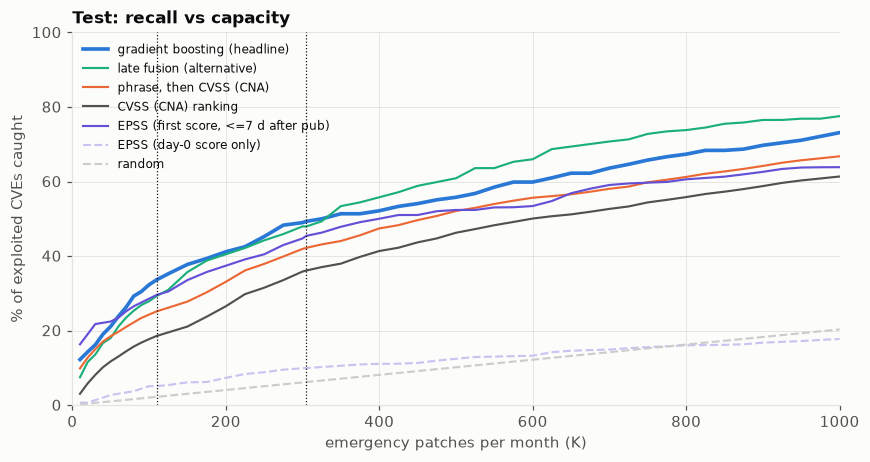

In [2]:
rec = T("06_recall").set_index("method"); dif = T("06_diffs"); own = T("06_own_capacity").set_index("rule"); curve = T("06_recall_vs_k").set_index("K per month")
display(rec[["recall@110 [95% CI]", "recall@305 [95% CI]", "PR-AUC"]].round(3))
d = dif[dif["K"] == 110].set_index("headline minus")
display(d.assign(**{"difference [95% CI]": [f"{a:+.1f} [{b:+.1f}, {c:+.1f}]" for a, b, c in zip(d["diff (pts)"], d["CI lo"], d["CI hi"])]})[["difference [95% CI]", "P(headline better)"]])
print("rules at their own capacity vs the model at the same K:"); display(own.round(1))
COL = {HEAD: BLUE, ALT: AQUA, "phrase, then CVSS (CNA)": ORANGE, "CVSS (CNA) ranking": INK2, EPSS7: VIOLET, "EPSS (day-0 score only)": "#c9c3f0", "random": "#cccccc"}
fig, ax = plt.subplots(figsize=(9, 4.4))
for m in COL: ax.plot(curve.index, 100 * curve[m], color=COL[m], lw=2.4 if m == HEAD else 1.4, ls="--" if m in ("random", "EPSS (day-0 score only)") else "-", label=m)
for k in (110, 305): ax.axvline(k, color=INK, lw=0.8, ls=":")
ax.set(xlim=(0, 1000), ylim=(0, 100), xlabel="emergency patches per month (K)", ylabel="% of exploited CVEs caught"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Test: recall vs capacity", loc="left"); save(fig, "3_01_recall_vs_k")

**Takeaway**: **Gradient boosting caught 33.7% [28–39] of exploited CVEs with 110 patches a month**, vs 25.2% for the best rule (+8.5 [+1.7, +15.3], P 99%) and 18.6% for CVSS ranking (+15.1). It leads **every day-0 rule at every capacity from 10 to 1,000** (smallest lead +1.2 points at K = 30), and **at the CVSS ≥ 9 rule's own 385 patches a month catches 51.7% vs 41.2%** — so the conclusion does not hinge on the assumed CVSS ≥ 9 policy or on K. Test recall is below validation (47.1%): see drift in notebook 4.

## 3.2 EPSS — the industry benchmark, with caveats
1. **Lookahead:** most CVEs get their first EPSS score the day *after* publication (shown ≤ 7 days, by day 1 and day-0 only).
2. **Different target:** exploitation activity in the next 30 days, not KEV within 90 days. 3. **EPSS v4** replaced v3 on 2025-03-17.
4. **EPSS may use the label:** *assumed* that EPSS lists CISA KEV among its sources (documentation not reachable from the
   project sandbox) → the pre-registered **"not yet in KEV"** analysis keeps only exploited CVEs added to KEV *after* the EPSS score date.

,negatives,positives,share of CVEs %
first EPSS score at,,,
0 d,30562,62,29.9
1 d,71039,230,69.5
2 d,223,0,0.2
3 d,146,2,0.1
4 d,203,0,0.2
5 d,85,0,0.1
none within 7 d,9,0,0.0


,CVEs,positives,months,gradient boosting (headline) @110,late fusion (alternative) @110,"phrase, then CVSS (CNA) @110","EPSS (first score, <=7 d after pub) @110",EPSS (score by day 1) @110
EPSS model period,,,,,,,,
before 2025-03-17 (EPSS v3),9742,44,3,43.2 [29–59],46.6 [30–63],26.9 [14–40],40.9 [26–56],40.9 [26–56]
from 2025-03-17 (EPSS v4),92819,250,18,32.8 [27–39],27.5 [22–33],25.3 [20–31],30.8 [25–36],30.8 [25–36]


,all 294 exploited,185 not yet in KEV at the EPSS date
method,,
gradient boosting (headline),33.7 [28–39],30.4 [24–37]
late fusion (alternative),29.3 [24–35],23.8 [17–29]
"phrase, then CVSS (CNA)",25.2 [20–30],29.4 [23–36]
CVSS (CNA) ranking,18.6 [14–23],22.1 [16–28]
generous CVSS (fallback) ranking,17.8 [13–22],20.3 [14–27]
"EPSS (first score, <=7 d after pub)",29.6 [24–35],14.6 [9–20]
EPSS (day-0 score only),5.1 [3–8],6.5 [3–10]


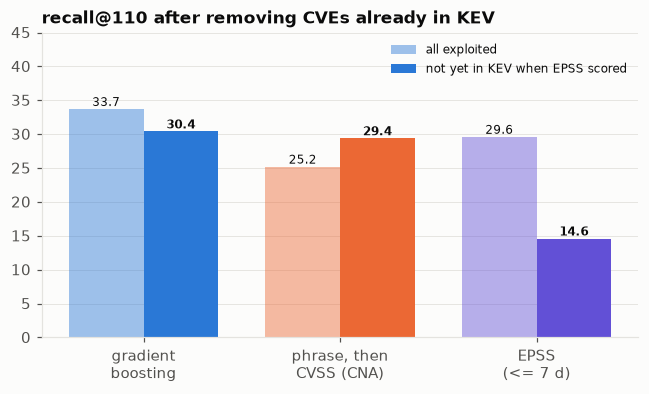

In [3]:
cov = T("06_epss_coverage").set_index("first EPSS score at"); display(cov.round(1))
display(T("06_epss_v3_v4").set_index("EPSS model period"))
nyk = T("06_not_yet_in_kev").set_index("EPSS variant defining the cut")
methods = [HEAD, ALT, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", "generous CVSS (fallback) ranking", EPSS7, "EPSS (day-0 score only)"]
tbl = pd.DataFrame({"all 294 exploited": rec.loc[methods, "recall@110 [95% CI]"], "185 not yet in KEV at the EPSS date": [nyk.loc[EPSS7, f"{m} @110"] for m in methods]}); display(tbl)
mm = [HEAD, "phrase, then CVSS (CNA)", EPSS7]; x = np.arange(3); w = 0.38
a = [pt(rec.loc[m, "recall@110 [95% CI]"]) for m in mm]; b = [pt(nyk.loc[EPSS7, f"{m} @110"]) for m in mm]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x - w/2, a, w, color=[COL[m] for m in mm], alpha=0.45, label="all exploited"); ax.bar(x + w/2, b, w, color=[COL[m] for m in mm], label="not yet in KEV when EPSS scored")
for xi, (u, v) in enumerate(zip(a, b)):
    ax.annotate(f"{u:.1f}", (xi - w/2, u), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8); ax.annotate(f"{v:.1f}", (xi + w/2, v), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8, weight="bold")
ax.set_xticks(x, ["gradient\nboosting", "phrase, then\nCVSS (CNA)", "EPSS\n(<= 7 d)"]); ax.grid(axis="x", visible=False); ax.set_ylim(0, 45); ax.legend(frameon=False, fontsize=8)
ax.set_title("recall@110 after removing CVEs already in KEV", loc="left"); save(fig, "3_02_not_yet_in_kev")

**Takeaway**: Against EPSS the model is ahead but not clearly (+4.1 [−2.7, +10.5], P 86%); EPSS ranks its very top better at ≤ 50 patches a month, and only 30% of CVEs have an EPSS score on publication day (day-0 EPSS: 5.1%). **But 109 of the 294 exploited CVEs (37%) were already in KEV when EPSS produced its score; on the other 185, EPSS falls to 14.6% [9–20] while the model keeps 30.4% [24–37]** (best rule 29.4%). The gap is similar under EPSS v3 (43.2 vs 40.9) and v4 (32.8 vs 30.8).

## 3.3 Robustness (pre-registered): walk-forward 2022-24 → 2025, quarters, calibration

,CVEs,positives,months,gradient boosting (headline) @110,late fusion (alternative) @110,"phrase, then CVSS (CNA) @110","EPSS (first score, <=7 d after pub) @110",EPSS (score by day 1) @110
year,,,,,,,,
2025,48150,159,12,41.9 [34–50],39.1 [31–47],29.5 [22–37],29.6 [23–37],29.6 [23–37]
2026,54411,135,8,23.9 [17–32],17.8 [12–25],20.0 [13–27],29.6 [21–37],29.6 [21–37]


,CVEs,positives,months,gradient boosting (headline) @110,late fusion (alternative) @110,"phrase, then CVSS (CNA) @110","EPSS (first score, <=7 d after pub) @110",EPSS (score by day 1) @110
quarter,,,,,,,,
2025Q1,11946,46,3,39.1 [23–52],40.2 [26–55],23.3 [11–36],23.9 [12–36],23.9 [12–36]
2025Q2,11695,42,3,44.4 [31–61],39.7 [25–54],33.8 [19–49],35.7 [21–50],35.7 [21–50]
2025Q3,11725,36,3,38.9 [21–56],38.9 [21–53],31.3 [17–48],25.0 [12–42],25.0 [12–42]
2025Q4,12784,35,3,45.7 [29–63],37.1 [22–54],30.8 [14–47],34.3 [18–51],34.3 [18–51]
2026Q1,15152,40,3,37.8 [23–54],52.5 [37–69],18.1 [6–32],47.5 [31–62],47.5 [31–62]
2026Q2,20688,56,3,25.3 [15–38],5.4 [0–13],28.3 [16–41],21.4 [11–33],21.4 [11–33]
2026Q3,18571,39,2,7.7 [0–18],0.0 [0–0],10.3 [2–21],23.1 [11–36],23.1 [11–36]


,0
Brier (calibrated),0.002816
Brier (constant base rate),0.002858
log loss (calibrated),0.016924
log loss (constant),0.019645
mean predicted,0.004154
observed rate,0.002867
note,out-of-sample


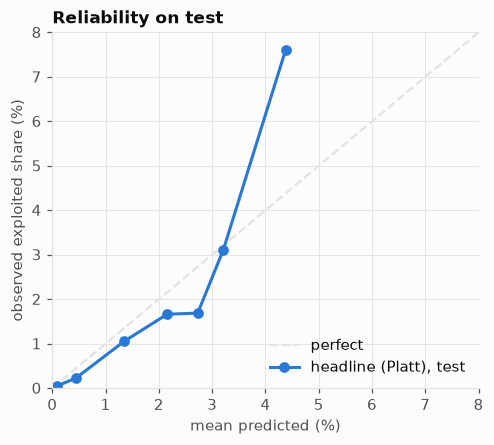

In [4]:
display(T("06_by_year").set_index("year")); display(T("06_by_quarter").set_index("quarter"))
cal = T("06_calibration"); display(cal.T)
bins = T("06_calibration_bins"); fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot([0, 8], [0, 8], color=GRID, ls="--", lw=1.5, label="perfect"); ax.plot(100 * bins["predicted"], 100 * bins["observed"], "o-", color=BLUE, lw=2, label="headline (Platt), test")
ax.set(xlim=(0, 8), ylim=(0, 8), xlabel="mean predicted (%)", ylabel="observed exploited share (%)"); ax.legend(frameon=False, loc="lower right"); ax.set_title("Reliability on test", loc="left"); save(fig, "3_03_calibration")

**Takeaway**: **Test year 2025 (= walk-forward 2022-24 → 2025): 41.9% [34–50]**, in line with the dev periods; **2026 (Jan–Aug): 23.9% [17–32]**, falling to 7.7% in Jul–Aug while EPSS stays at 29.6% in both years. Probabilities are only modestly better than a constant (Brier 0.002816 vs 0.002858), over-predict on average (0.42% vs 0.29%) and under-predict in the top 0.5% (4.4% vs 7.6%) — ranking is what was validated.